In [1]:
import time
import statistics
import matplotlib.pyplot as plt

In [2]:
# Function to calculate prefix averages using repeated summation
def prefix_average1(data):
    averages = []

    for i in range(len(data)):
        total = 0

        # Calculate the sum of elements from the beginning to the current index
        for j in range(i + 1):
            total += data[j]

        averages.append(total / (i + 1))

    return averages

In [3]:
# Function to calculate prefix averages using a running sum
def prefix_average2(data):
    averages = []
    total = 0

    # Maintain the running sum while traversing the list
    for i in range(len(data)):
        total += data[i]
        averages.append(total / (i + 1))

    return averages

In [4]:
# Test cases for prefix averages
test_cases = [
    [10],
    [1, 2, 3, 4, 5],
    [-1, -2, -3, -4],
    [5, -2, 8, -4, 3],
    []
]

# Compare the outputs of both methods
for data in test_cases:
    print("Input:", data)
    print("Prefix Average 1:", prefix_average1(data))
    print("Prefix Average 2:", prefix_average2(data))
    print("Outputs Match:", prefix_average1(data) == prefix_average2(data))
    print()

Input: [10]
Prefix Average 1: [10.0]
Prefix Average 2: [10.0]
Outputs Match: True

Input: [1, 2, 3, 4, 5]
Prefix Average 1: [1.0, 1.5, 2.0, 2.5, 3.0]
Prefix Average 2: [1.0, 1.5, 2.0, 2.5, 3.0]
Outputs Match: True

Input: [-1, -2, -3, -4]
Prefix Average 1: [-1.0, -1.5, -2.0, -2.5]
Prefix Average 2: [-1.0, -1.5, -2.0, -2.5]
Outputs Match: True

Input: [5, -2, 8, -4, 3]
Prefix Average 1: [5.0, 1.5, 3.6666666666666665, 1.75, 2.0]
Prefix Average 2: [5.0, 1.5, 3.6666666666666665, 1.75, 2.0]
Outputs Match: True

Input: []
Prefix Average 1: []
Prefix Average 2: []
Outputs Match: True



In [5]:
# Function to measure execution time
def measure_time(function, data, trials=5):
    times = []

    for i in range(trials):
        start = time.perf_counter()
        function(data)
        end = time.perf_counter()

        times.append(end - start)

    return statistics.median(times)

In [6]:
# Input sizes for benchmarking
sizes = [100, 500, 1000, 2000, 4000, 8000]

time1 = []
time2 = []

# Measure execution time for both methods
for n in sizes:
    data = list(range(1, n + 1))

    time1.append(measure_time(prefix_average1, data))
    time2.append(measure_time(prefix_average2, data))

print("Benchmark completed.")

Benchmark completed.


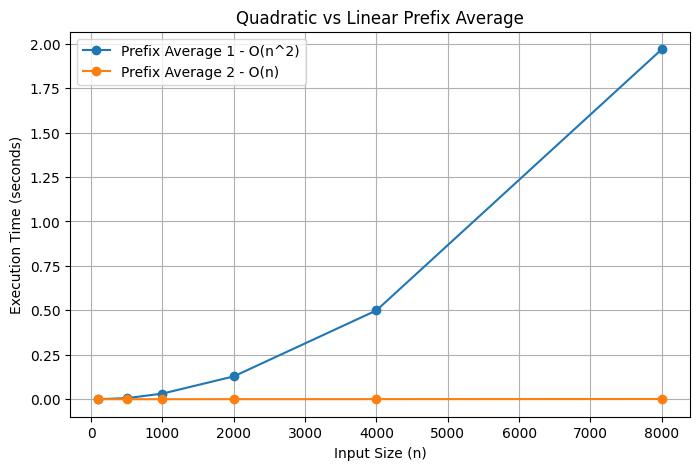

In [7]:
# Plot execution time of both prefix average methods
plt.figure(figsize=(8, 5))

plt.plot(sizes, time1, marker='o', label='Prefix Average 1 - O(n^2)')
plt.plot(sizes, time2, marker='o', label='Prefix Average 2 - O(n)')

plt.xlabel("Input Size (n)")
plt.ylabel("Execution Time (seconds)")
plt.title("Quadratic vs Linear Prefix Average")
plt.legend()
plt.grid(True)

plt.show()

In [8]:
# Display execution time for each input size
print("Input Size | Method 1 Time | Method 2 Time")
print("------------------------------------------")

for i in range(len(sizes)):
    print(sizes[i], "|", time1[i], "|", time2[i])

Input Size | Method 1 Time | Method 2 Time
------------------------------------------
100 | 0.0002066000015474856 | 1.0800024028867483e-05
500 | 0.005958599969744682 | 6.699998630210757e-05
1000 | 0.03158060001442209 | 0.00015129998791962862
2000 | 0.12851209996733814 | 0.0003163999645039439
4000 | 0.4997745000291616 | 0.0005432000034488738
8000 | 1.9689783999929205 | 0.001166699978057295
